# Fundamentals of Machine Learning — Exercise 5

## Gradient Descent, Linear Regression, and Logistic Regression

The previous exercises focused on finding structure without a target variable. We now move to **supervised learning**.

This exercise follows one central idea:

> A model is fitted by changing its parameters so that a loss function becomes smaller.

We will use gradient descent first for regression and then for binary classification.

The working rhythm remains:

> **question → prediction → computation → visualisation → interpretation → verification**

### Learning outcomes

After completing this exercise, you should be able to:

- explain the roles of features, targets, predictions, residuals, and loss,
- describe a gradient as a direction of local change,
- perform and verify one gradient-descent update by hand,
- explain the effect of the learning rate,
- fit linear regression using a prepared NumPy implementation,
- explain why logistic regression produces probabilities,
- distinguish probability estimation from the final decision threshold,
- interpret a confusion matrix, precision, recall, F1-score, and ROC-AUC,
- explain why accuracy can be misleading for an imbalanced dataset,
- avoid fitting preprocessing on the test set,
- use AI as a tutor that questions reasoning instead of generating the solution.

**Recommended duration:** 110–120 minutes.

## How to work in this exercise

Most implementation is prepared. Your main tasks are to:

1. make a prediction before running an experiment,
2. complete a small number of mathematically meaningful lines,
3. explain the result using the loss function and model behaviour,
4. verify an important claim numerically,
5. distinguish a modelling decision from a software default.

Do not judge a model from one metric alone.

## 0. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes, make_classification
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', context='notebook')
RANDOM_STATE = 42

## 1. A line, its predictions, and its errors

For one feature, a linear model is

$$
\hat{y} = wx + b.
$$

- `w` is the slope,
- `b` is the intercept,
- $y - \hat{y}$ is a residual.

We will begin with a tiny dataset where the correct relationship is almost visible.

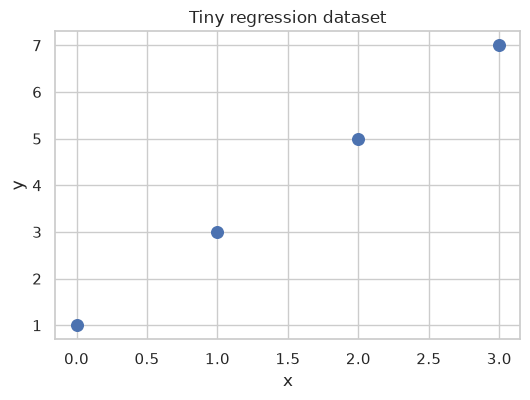

In [2]:
x_small = np.array([0.0, 1.0, 2.0, 3.0])
y_small = np.array([1.0, 3.0, 5.0, 7.0])

plt.figure(figsize=(6, 4))
plt.scatter(x_small, y_small, s=70)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Tiny regression dataset')
plt.show()

### Predict before computing

1. What values of `w` and `b` appear plausible?
2. If we start with `w=0` and `b=0`, will the model underpredict or overpredict?
3. Should the next update increase or decrease `w`?

In [3]:
def predict_linear(x, w, b):
    # TODO: Implement the linear function    
    return w * x + b

w0, b0 = 0.0, 0.0
prediction0 = predict_linear(x_small, w0, b0)

pd.DataFrame({
    'x': x_small,
    'y': y_small,
    'prediction': prediction0,
    'residual': y_small - prediction0,
})

,x,y,prediction,residual
0,0.0,1.0,0.0,1.0
1,1.0,3.0,0.0,3.0
2,2.0,5.0,0.0,5.0
3,3.0,7.0,0.0,7.0


## Loss function

In machine learning, training a model means finding parameters that minimize a **loss function**.

Consider a simple linear regression model:

$$
\hat{y}_i = wx_i + b
$$

where $w$ is the weight, $b$ is the bias, and $\hat{y}_i$ is the predicted value.

We measure the prediction error using the **Mean Squared Error (MSE)**:

$$
MSE(w,b) = \frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)^2
$$

In [5]:
def mse_loss(y_true, y_pred):
    # TODO: Implement the mean squared error loss function
    return np.mean((y_pred - y_true) ** 2)

print('Initial MSE:', mse_loss(y_small, prediction0))

Initial MSE: 21.0


## READING(5 min) - Finding the minimum of a function 



Substituting the prediction formula of linear regressin model in formula for MSE:

$$
MSE(w,b) = \frac{1}{n}\sum_{i=1}^{n}(wx_i+b-y_i)^2
$$

Our goal is to find the values of $w$ and $b$ that minimize this function.

### Analytical approach

For a differentiable function of one variable, stationary points can be found by solving:

$$
f'(x)=0
$$

For a function of multiple variables, we calculate the **partial derivatives** and set them equal to zero:

$$
\frac{\partial MSE}{\partial w}=0,
\qquad
\frac{\partial MSE}{\partial b}=0
$$

These equations identify stationary points, which may be minima, maxima, or saddle points.

For linear regression with MSE, the loss function is convex, so any stationary point is a global minimum.

However, for more complex models, finding an analytical solution may be difficult or impossible. Instead, we can use an iterative optimization algorithm called **Gradient Descent**.

### Gradient Descent – Finding the Minimum of a Function

Consider the function:

$$
f(x) = x^2
$$

Its derivative is:

$$
f'(x) = 2x
$$

We know that this function has a global minimum at $x=0$.

Instead of finding the minimum analytically, we will use **gradient descent**.

Starting from an initial value $x_0$, we repeatedly update $x$ using:

$$
x_{k+1} = x_k - \alpha f'(x_k)
$$

where $\alpha$ is the **learning rate**.

At each iteration:
1. Calculate the derivative at the current position.
2. Move in the opposite direction of the derivative.
3. Repeat until we approach the minimum.

**Experiment:** Change the learning rate and observe how it affects convergence.

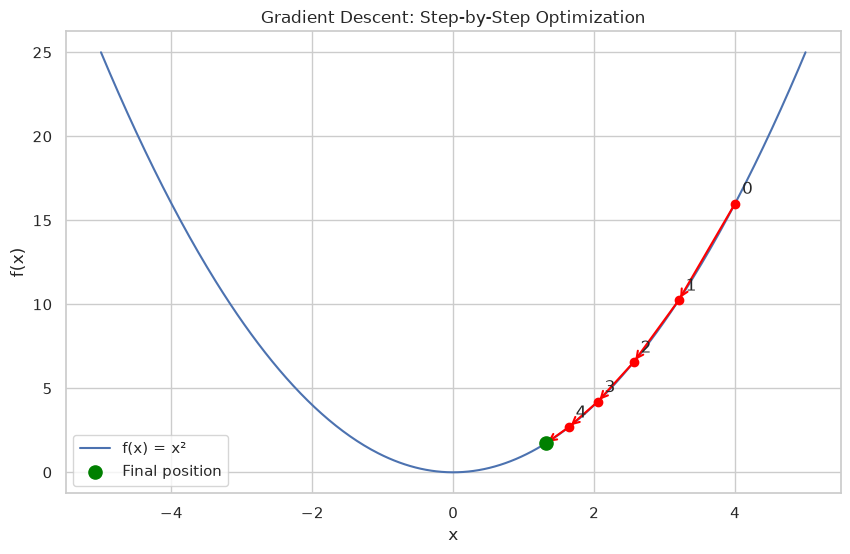

Final x: 1.310720
Final f(x): 1.717987


In [14]:
# Function and its derivative
def f(x):
    return x**2

def df(x):
    return 2 * x

# Parameters
x = 4.0
learning_rate = 0.1
iterations = 5

# Gradient descent
history = [x]

for i in range(iterations):
    gradient = df(x)
    x = x - learning_rate * gradient
    history.append(x)

# Visualization
x_values = np.linspace(-5, 5, 400)
y_values = f(x_values)

plt.figure(figsize=(10, 6))
plt.plot(x_values, y_values, label="f(x) = x²")

# Plot each gradient descent step
for i in range(len(history) - 1):
    x1, x2 = history[i], history[i + 1]
    plt.scatter(x1, f(x1), color="red", zorder=3)
    plt.annotate(
        "",
        xy=(x2, f(x2)),
        xytext=(x1, f(x1)),
        arrowprops=dict(arrowstyle="->", color="red", lw=1.5)
    )
    plt.annotate(str(i), (x1, f(x1)),
                 xytext=(5, 7), textcoords="offset points")

plt.scatter(history[-1], f(history[-1]),
            color="green", s=90, zorder=4,
            label="Final position")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Gradient Descent: Step-by-Step Optimization")
plt.legend()
plt.grid(True)
plt.show()

print(f"Final x: {x:.6f}")
print(f"Final f(x): {f(x):.6f}")




## 2. Gradient Descent

The derivative tells us how a function changes when its input changes.

- A **positive derivative** means the function increases as the parameter increases.
- A **negative derivative** means the function decreases as the parameter increases.
- A **zero derivative** indicates a stationary point.

The **gradient** is a vector of partial derivatives. It points in the direction of the steepest local increase of the function.

To minimize the loss, gradient descent updates the parameters in the **opposite direction** of the gradient.

### Tasks: Derive the gradients

Given the MSE function:

$$
MSE(w,b)=\frac{1}{n}\sum_{i=1}^{n}(wx_i+b-y_i)^2
$$

**Task 1:** Calculate the partial derivative of MSE with respect to $w$.

$$
\frac{\partial MSE}{\partial w} = \; ?
$$

**Task 2:** Calculate the partial derivative of MSE with respect to $b$.

$$
\frac{\partial MSE}{\partial b} = \; ?
$$

*Hint: Use the chain rule and set $u = wx_i+b-y_i$. When differentiating with respect to one parameter, treat the other parameter as a constant.*

## 3. One gradient-descent step

The resulting gradients are:

$$
\frac{\partial MSE}{\partial w} =
\frac{2}{n}\sum_{i=1}^{n}x_i(\hat{y}_i-y_i)
$$

$$
\frac{\partial MSE}{\partial b} =
\frac{2}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)
$$

Gradient descent updates the parameters in the **opposite** direction of the gradient:

$$
w_{new}=w-\alpha\frac{\partial MSE}{\partial w}
$$

$$
b_{new}=b-\alpha\frac{\partial MSE}{\partial b}
$$

Here, $\alpha$ is the **learning rate**, which controls the size of each update.

By repeating these steps, the algorithm attempts to find parameters that minimize the loss function.

### Activity 1 - Complete only the meaningful lines

Fill the two gradient expressions. Do not rewrite the surrounding function.

In [15]:
def linear_gradients(x, y, w, b):
    prediction = predict_linear(x, w, b)
    # TODO: implement the error term from prediction and y
    error = prediction - y

    # TODO: complete the two lines below.
    grad_w = 2 * np.mean(error * x)
    grad_b = 2 * np.mean(error)

    return grad_w, grad_b


grad_w0, grad_b0 = linear_gradients(x_small, y_small, w0, b0)
print('Gradient for w:', grad_w0)
print('Gradient for b:', grad_b0)

assert grad_w0 == -17.0
assert grad_b0 == -8.0

Gradient for w: -17.0
Gradient for b: -8.0


Before running the update, interpret the signs:

> A negative gradient for `w` means that increasing `w` should __________ the loss locally.
>
> We subtract the gradient, therefore the new `w` will __________.

In [17]:
LEARNING_RATE = 0.05

# TODO: Update the parameters using the computed gradients
w1 = w0 - LEARNING_RATE * grad_w0
b1 = b0 - LEARNING_RATE * grad_b0
prediction1 = predict_linear(x_small, w1, b1)

print('Updated w:', w1)
print('Updated b:', b1)
print('MSE before:', mse_loss(y_small, prediction0))
print('MSE after one step:', mse_loss(y_small, prediction1))

Updated w: 0.8500000000000001
Updated b: 0.4
MSE before: 21.0
MSE after one step: 7.05875


## 3. Learning rate: too small, useful, or unstable?

We now run the same algorithm for several learning rates.

Predict first:

| Learning rate | Expected behaviour |
|---:|---|
| 0.001 |  |
| 0.05 |  |
| 0.50 |  |

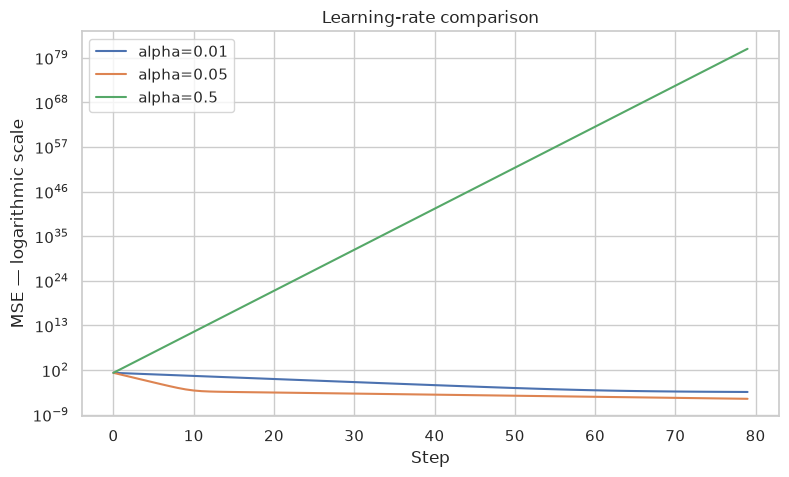

In [18]:
def fit_linear_gd(x, y, learning_rate, n_steps=80):
    w, b = 0.0, 0.0
    history = []

    for step in range(n_steps):
        prediction = predict_linear(x, w, b)
        loss = mse_loss(y, prediction)
        history.append({'step': step, 'loss': loss, 'w': w, 'b': b})

        grad_w, grad_b = linear_gradients(x, y, w, b)
        w -= learning_rate * grad_w
        b -= learning_rate * grad_b

        if not np.isfinite(w + b):
            break

    return w, b, pd.DataFrame(history)


learning_rates = [0.01, 0.05, 0.50]
linear_runs = {}

plt.figure(figsize=(9, 5))

for rate in learning_rates:
    w_fit, b_fit, history = fit_linear_gd(
        x_small,
        y_small,
        learning_rate=rate,
        n_steps=80,
    )
    linear_runs[rate] = (w_fit, b_fit, history)
    plt.plot(history['step'], history['loss'], label=f'alpha={rate}')

plt.yscale('log')
plt.xlabel('Step')
plt.ylabel('MSE — logarithmic scale')
plt.title('Learning-rate comparison')
plt.legend()
plt.show()

### Activity 2 - Explain the trajectories

For each learning rate, describe:

- speed of progress,
- stability,
- final loss.

Then complete:

> A learning rate is not “good” because it is large or small. It is useful when __________.

## 4. Linear regression on real data

We use the built-in diabetes regression dataset. The target is a quantitative disease-progression measure one year after baseline.

We will compare:

- our NumPy gradient-descent model,
- scikit-learn's direct `LinearRegression` solution.

To keep the from-scratch model readable, we use one feature: `bmi`.

In [19]:
diabetes = load_diabetes(as_frame=True)
diabetes_frame = diabetes.frame.copy()

display(diabetes_frame[['bmi', 'target']].head())

X_reg = diabetes_frame[['bmi']].to_numpy()
y_reg = diabetes_frame['target'].to_numpy()

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.25,
    random_state=RANDOM_STATE,
)

x_scaler = StandardScaler()
y_mean = y_train_reg.mean()
y_std = y_train_reg.std()

X_train_reg_scaled = x_scaler.fit_transform(X_train_reg).ravel()
X_test_reg_scaled = x_scaler.transform(X_test_reg).ravel()
y_train_reg_scaled = (y_train_reg - y_mean) / y_std

,bmi,target
0,0.061696,151.0
1,-0.051474,75.0
2,0.044451,141.0
3,-0.011595,206.0
4,-0.036385,135.0


### Leakage checkpoint

Why is the scaler fitted only on the training set?

What information from the test set would leak if we fitted it before splitting?

In [20]:
w_reg, b_reg, reg_history = fit_linear_gd(
    X_train_reg_scaled,
    y_train_reg_scaled,
    learning_rate=0.05,
    n_steps=250,
)

pred_test_scaled = predict_linear(X_test_reg_scaled, w_reg, b_reg)
pred_test_gd = pred_test_scaled * y_std + y_mean

sk_model = LinearRegression()
sk_model.fit(X_train_reg, y_train_reg)
pred_test_sk = sk_model.predict(X_test_reg)

regression_results = pd.DataFrame([
    {
        'model': 'NumPy gradient descent',
        'MAE': mean_absolute_error(y_test_reg, pred_test_gd),
        'RMSE': mean_squared_error(y_test_reg, pred_test_gd) ** 0.5,
    },
    {
        'model': 'scikit-learn LinearRegression',
        'MAE': mean_absolute_error(y_test_reg, pred_test_sk),
        'RMSE': mean_squared_error(y_test_reg, pred_test_sk) ** 0.5,
    },
])

regression_results.round(2)

,model,MAE,RMSE
0,NumPy gradient descent,49.81,61.45
1,scikit-learn LinearRegression,49.81,61.45


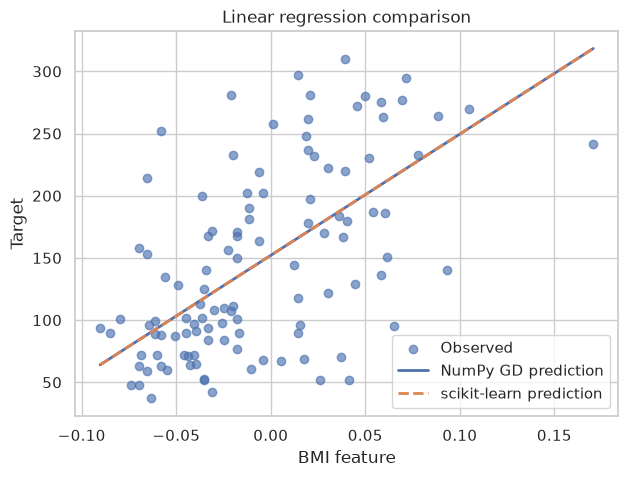

In [21]:
plt.figure(figsize=(7, 5))
plt.scatter(X_test_reg[:, 0], y_test_reg, alpha=0.65, label='Observed')

order = np.argsort(X_test_reg[:, 0])
plt.plot(
    X_test_reg[order, 0],
    pred_test_gd[order],
    linewidth=2,
    label='NumPy GD prediction',
)
plt.plot(
    X_test_reg[order, 0],
    pred_test_sk[order],
    linestyle='--',
    linewidth=2,
    label='scikit-learn prediction',
)

plt.xlabel('BMI feature')
plt.ylabel('Target')
plt.title('Linear regression comparison')
plt.legend()
plt.show()

## 5. From Linear Regression to Logistic Regression

### 5.1 Regression vs. Classification

So far, we have used linear regression to predict a continuous numerical value:

$$
\hat{y} = wx+b
$$

However, what if we want to predict a **category** instead of a numerical value?

For example:

- Will a patient develop a disease? (Yes / No)
- Is an email spam? (Spam / Not spam)
- Will a customer leave a service? (Yes / No)

In binary classification, the target variable has only two possible values:

$$
y \in \{0,1\}
$$

**Question:** Can we use linear regression for binary classification?



### Geometric Interpretation of Logistic Regression

Consider a binary classification problem with two input features, $x_1$ and $x_2$. Each observation is represented as a point in a two-dimensional space and belongs to one of two classes:

$$
y \in \{0,1\}
$$

Our goal is to find a **decision boundary** that separates the two classes.

We start with a linear function:

$$
z = w_1x_1 + w_2x_2 + b
$$

where:

- $w_1, w_2$ are the weights that determine the orientation of the decision boundary.
- $b$ is the bias that controls its position.
- $z$ is the linear score.

The decision boundary consists of all points where:

$$
w_1x_1 + w_2x_2 + b = 0
$$

In two dimensions, this equation describes a **straight line**. In three dimensions, it describes a plane, and in higher dimensions, a hyperplane.

The line divides the feature space into two regions:

$$
z < 0 \quad \Rightarrow \quad \text{Class 0}
$$

$$
z \geq 0 \quad \Rightarrow \quad \text{Class 1}
$$

### From the General Equation to the Slope-Intercept Form

You may already know the equation of a straight line in the **slope-intercept form**:

$$
y=ax+c
$$

where $a$ is the slope and $c$ is the intercept with the vertical axis.

In logistic regression, we use the **general form** of a line:

$$
w_1x_1+w_2x_2+b=0
$$

Both equations describe a straight line in two-dimensional space.

To see their relationship, let $x_1=x$ and $x_2=y$:

$$
w_1x+w_2y+b=0
$$

Solving for $y$ (assuming $w_2\neq 0$):

$$
y=-\frac{w_1}{w_2}x-\frac{b}{w_2}
$$

Comparing this with $y=ax+c$, we obtain:

$$
\boxed{a=-\frac{w_1}{w_2}, \qquad c=-\frac{b}{w_2}}
$$

**Why do we use the general form in logistic regression?**

- It can represent any straight line, including vertical lines.
- It can be extended to higher-dimensional spaces.
- The weight vector $\mathbf{w}=(w_1,w_2)$ is perpendicular to the decision boundary.

For $n$ input features, the decision boundary becomes:

$$
\mathbf{w}^T\mathbf{x}+b=0
$$

This equation describes a **hyperplane** in an $n$-dimensional feature space, provided that $\mathbf{w}\neq\mathbf{0}$.

**Question:** What happens to the decision boundary when $w_2=0$? Can you still express it in the form $y=ax+c$?

**Experiment:** In the following example, manually change the weights and bias to find a decision boundary that separates the two classes.

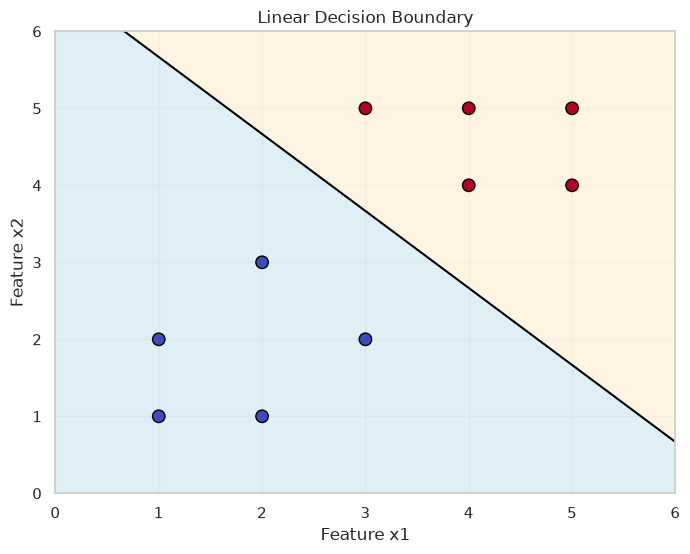

Accuracy: 1.0


In [25]:
# Two-dimensional dataset
X = np.array([
    [1, 1], [1, 2], [2, 1], [2, 3], [3, 2],
    [4, 4], [4, 5], [5, 4], [5, 5], [3, 5]
])

y = np.array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1])

# Parameters of the linear model
w1 = 0.15
w2 = 0.15
b = -1.0

# Linear scores and predicted classes
z = w1 * X[:, 0] + w2 * X[:, 1] + b
y_pred = (z >= 0).astype(int)

# Plot the decision regions
x1_grid, x2_grid = np.meshgrid(
    np.linspace(0, 6, 200),
    np.linspace(0, 6, 200)
)

z_grid = w1 * x1_grid + w2 * x2_grid + b

plt.figure(figsize=(8, 6))
plt.contourf(
    x1_grid, x2_grid, z_grid,
    levels=[-np.inf, 0, np.inf],
    colors=["lightblue", "moccasin"],
    alpha=0.4
)

plt.contour(
    x1_grid, x2_grid, z_grid,
    levels=[0], colors="black"
)

plt.scatter(
    X[:, 0], X[:, 1],
    c=y, cmap="coolwarm",
    edgecolors="black", s=80
)

plt.xlabel("Feature x1")
plt.ylabel("Feature x2")
plt.title("Linear Decision Boundary")
plt.xlim(0, 6)
plt.ylim(0, 6)
plt.grid(alpha=0.2)
plt.show()

print("Accuracy:", np.mean(y_pred == y))


### Tasks: Understanding the Decision Boundary

1. Change the values of `w1`, `w2`, and `b`. How does the decision boundary change?
2. What happens if `w1 = 0`? What happens if `w2 = 0`?
3. Find parameters that correctly classify all observations.
4. Can you always separate two classes using a straight line?
5. What geometric object represents the decision boundary when we have three input features?

**Questions:**

1. How do the weights $w_1$ and $w_2$ affect the orientation of the decision boundary?
2. What happens when you change only the bias $b$?
3. Can you find parameters that correctly classify all observations?
4. What happens if the two classes cannot be separated by a straight line?

**Next step:** We can now distinguish between the two classes using a linear score. Logistic regression extends this idea by applying the sigmoid function to convert the score into an estimated probability.

The problem is that linear regression can produce any real number:

$$
\hat{y} \in (-\infty,+\infty)
$$

A prediction of $-2.5$ or $1.8$ cannot be interpreted as a probability.

We therefore need a function that transforms the output of a linear model into a value between 0 and 1.

### 5.2 The Sigmoid Function

Logistic regression starts with the same linear combination:

$$
z = wx+b
$$

But instead of using $z$ directly as the prediction, we apply the **sigmoid function**:

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

The sigmoid has several useful properties:

- Its output is always between 0 and 1.
- When $z=0$, the output is $0.5$.
- Large positive values approach 1.
- Large negative values approach 0.

The logistic regression model is therefore:

$$
P(y=1\mid x)=\sigma(wx+b)
$$

For multiple input features:

$$
P(y=1\mid \mathbf{x})=\sigma(\mathbf{w}^T\mathbf{x}+b)
$$

The output is interpreted as the **estimated probability that the observation belongs to class 1**.

### 5.3 From Probability to Class

The model returns a probability, but classification requires a discrete label.

We can use a decision threshold:

$$
\hat{y} =
\begin{cases}
1 & \text{if } P(y=1\mid x)\geq 0.5\\
0 & \text{otherwise}
\end{cases}
$$

For example:

| Predicted probability | Predicted class |
|---|---|
| 0.12 | 0 |
| 0.43 | 0 |
| 0.67 | 1 |
| 0.91 | 1 |

**Questions:**

1. Why is the sigmoid function suitable for binary classification?
2. What happens if we change the threshold from 0.5 to 0.7?
3. Does a predicted probability of 0.8 guarantee that the observation belongs to class 1?

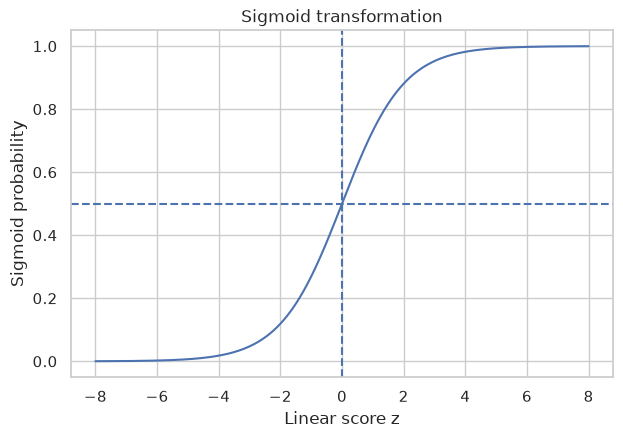

In [23]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


z_values = np.linspace(-8, 8, 300)

plt.figure(figsize=(7, 4.5))
plt.plot(z_values, sigmoid(z_values))
plt.axhline(0.5, linestyle='--')
plt.axvline(0, linestyle='--')
plt.xlabel('Linear score z')
plt.ylabel('Sigmoid probability')
plt.title('Sigmoid transformation')
plt.show()

## 6. An imbalanced classification problem

We generate a dataset with approximately 90% negatives and 10% positives.

Imagine that the positive class represents a case that requires further examination.

In [26]:
X_cls, y_cls = make_classification(
    n_samples=1600,
    n_features=8,
    n_informative=5,
    n_redundant=1,
    weights=[0.90, 0.10],
    class_sep=1.0,
    flip_y=0.02,
    random_state=RANDOM_STATE,
)

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls,
    y_cls,
    test_size=0.30,
    stratify=y_cls,
    random_state=RANDOM_STATE,
)

pd.Series(y_train_cls).value_counts(normalize=True).rename('proportion')

0    0.890179
1    0.109821
Name: proportion, dtype: float64

## Reading(5 min): Evaluating Classification Models

### Classification and Class Imbalance

In classification, we want to predict which class an observation belongs to.

However, classification datasets are not always balanced. For example, consider a dataset containing 100 observations:

- 90 observations belong to **class 0 (negative)**.
- 10 observations belong to **class 1 (positive)**.

This is called an **imbalanced dataset**, because one class is much more frequent than the other.

How can we determine whether a classification model performs well?

### Confusion Matrix

A confusion matrix compares the predicted classes with the actual classes.

For binary classification, we distinguish four possible outcomes:

| | Predicted 0 | Predicted 1 |
|---|---|---|
| **Actual 0** | TN = 85 | FP = 5 |
| **Actual 1** | FN = 4 | TP = 6 |

Where:

- **TP (True Positive):** The model correctly predicts class 1.
- **TN (True Negative):** The model correctly predicts class 0.
- **FP (False Positive):** The model predicts class 1, but the actual class is 0.
- **FN (False Negative):** The model predicts class 0, but the actual class is 1.

Using these four values, we can calculate several evaluation metrics.

### Accuracy

Accuracy measures the proportion of all correctly classified observations.

$$
Accuracy=\frac{TP+TN}{TP+TN+FP+FN}
$$

For our example:

$$
Accuracy=\frac{6+85}{100}=0.91
$$

The model correctly classifies **91% of all observations**.

However, accuracy can be misleading when the dataset is imbalanced.

### Precision

Precision measures how many observations predicted as positive are actually positive.

$$
Precision=\frac{TP}{TP+FP}
$$

For our example:

$$
Precision=\frac{6}{6+5}\approx0.545
$$

Only **54.5% of positive predictions are correct**.

Precision is important when false positive predictions are costly.

### Recall (Sensitivity)

Recall measures how many of the actual positive observations the model successfully identifies.

$$
Recall=\frac{TP}{TP+FN}
$$

For our example:

$$
Recall=\frac{6}{6+4}=0.6
$$

The model identifies **60% of all positive observations**.

Recall is important when missing a positive case is costly, for example when detecting a disease.

### F1-Score

Precision and recall measure different aspects of classification performance.

The F1-score combines them using their **harmonic mean**:

$$
F_1=2\cdot\frac{Precision\cdot Recall}{Precision+Recall}
$$

Equivalently:

$$
F_1=\frac{2TP}{2TP+FP+FN}
$$

For our example:

$$
F_1=\frac{2\cdot6}{2\cdot6+5+4}
=\frac{12}{21}\approx0.571
$$

The F1-score is approximately **57.1%**.

Unlike accuracy, the positive-class F1-score does not include true negatives. It is therefore useful when we want to evaluate how well the model identifies the positive class.

### Why Accuracy Can Be Misleading

Consider a simple classifier that always predicts class 0.

For our dataset:

- 90 observations are correctly classified.
- 10 positive observations are missed.
- No positive predictions are made.

Its accuracy is:

$$
Accuracy=\frac{90}{100}=0.90
$$

The classifier achieves **90% accuracy without identifying a single positive observation!**

Its recall is:

$$
Recall=\frac{0}{0+10}=0
$$

Its precision is mathematically undefined because it never predicts class 1. In scikit-learn, we can define this value as 0 using `zero_division=0`, giving an F1-score of 0 as well.

**Key takeaway:** A high accuracy does not necessarily mean that a classifier is useful, especially when classes are imbalanced. Always consider the evaluation metric that reflects the objective of your classification task.

### Questions

1. Why can a classifier achieve high accuracy without identifying any positive observations?
2. What is the difference between precision and recall?
3. Which metric would you prioritize when detecting a serious disease, where missing a positive case could have severe consequences?
4. Which metric would you prioritize when false alarms are very expensive?
5. Why might the F1-score be more informative than accuracy for an imbalanced dataset?

In [ ]:
baseline_prediction = np.zeros_like(y_test_cls)

baseline_metrics = {
    'accuracy': accuracy_score(y_test_cls, baseline_prediction),
    'precision': precision_score(y_test_cls, baseline_prediction, zero_division=0),
    'recall': recall_score(y_test_cls, baseline_prediction, zero_division=0),
    'F1': f1_score(y_test_cls, baseline_prediction, zero_division=0),
}

pd.Series(baseline_metrics).round(3)

### Activity 4 — Why accuracy is insufficient

Complete:

> The baseline accuracy is high because __________.
>
> The model is useless for the positive class because __________.
>
> Therefore, class distribution must be inspected before __________.

### Fit logistic regression correctly

The scaler is fitted on training data only. The model is also fitted on training data only.

In [ ]:
cls_scaler = StandardScaler()
X_train_cls_scaled = cls_scaler.fit_transform(X_train_cls)
X_test_cls_scaled = cls_scaler.transform(X_test_cls)

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE,
)
logistic_model.fit(X_train_cls_scaled, y_train_cls)

positive_probability = logistic_model.predict_proba(X_test_cls_scaled)[:, 1]

## 7. The decision threshold changes errors, not probabilities

### Reading: Not All Classification Errors Are Equally Costly

Imagine that we are developing an AI system to screen patients for a serious disease.

Assume the following hypothetical situation:

- If the disease is detected early, effective treatment is available.
- If the disease is not detected, the patient may die without treatment.
- A positive screening result leads to additional medical examinations.

Our classifier predicts whether a patient has the disease.

There are four possible outcomes:

| Actual condition | Model prediction | Outcome |
|---|---|---|
| Healthy | Healthy | True Negative (TN) - No unnecessary treatment or examination |
| Healthy | Diseased | False Positive (FP) - Unnecessary examinations, anxiety, and possible costs |
| Diseased | Diseased | True Positive (TP) - Disease detected, treatment can begin |
| Diseased | Healthy | False Negative (FN) - Disease missed, potentially fatal consequences |

### A Question of Consequences

**Imagine you are the patient. Which mistake would you consider worse?**

**A.** You are healthy, but the model incorrectly predicts that you have the disease. You undergo unnecessary examinations and experience anxiety.

**B.** You have the disease, but the model incorrectly predicts that you are healthy. You are reassured, receive no treatment, and the disease progresses.

**Questions:**

1. Which of these two errors would you prefer to avoid?
2. Which error corresponds to a false positive (FP), and which to a false negative (FN)?
3. Should both errors have the same importance when evaluating the classifier?
4. If we want to avoid missing diseased patients, should we increase or decrease the decision threshold?
5. Which metric becomes particularly important in this situation: precision or recall?

### The Decision Threshold

Logistic regression estimates the probability of belonging to the positive class:

$$
P(y=1\mid\mathbf{x})
$$

We then choose a threshold $t$ to make the final decision:

$$
\hat{y}=
\begin{cases}
1 & \text{if }P(y=1\mid\mathbf{x})\geq t\\
0 & \text{otherwise}
\end{cases}
$$

A lower threshold generally means:

- More patients are classified as positive.
- Fewer actual cases are missed (higher or equal recall).
- More healthy patients may be incorrectly classified as positive (more false positives).

A higher threshold generally means:

- Fewer patients are classified as positive.
- More actual cases may be missed.
- Fewer healthy patients are incorrectly classified as positive.

**Key idea:** The threshold is not simply a mathematical parameter. Its selection reflects the consequences of different classification errors.

In medical screening, we may prefer higher recall even at the cost of more false positives. However, the appropriate threshold depends on the disease, available treatments, follow-up examinations, and the consequences of both types of errors.


We compare three thresholds.

Predict before running:

| Threshold | Expected positive predictions | Expected recall | Expected precision |
|---:|---|---|---|
| 0.30 |  |  |  |
| 0.50 |  |  |  |
| 0.70 |  |  |  |

In [ ]:
def metrics_at_threshold(y_true, probability, threshold):
    prediction = (probability >= threshold).astype(int)
    return {
        'threshold': threshold,
        'predicted positives': int(prediction.sum()),
        'accuracy': accuracy_score(y_true, prediction),
        'precision': precision_score(y_true, prediction, zero_division=0),
        'recall': recall_score(y_true, prediction, zero_division=0),
        'F1': f1_score(y_true, prediction, zero_division=0),        
    }


threshold_table = pd.DataFrame([
    metrics_at_threshold(y_test_cls, positive_probability, threshold)
    for threshold in [0.30, 0.50, 0.70]
])

threshold_table.round(3)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for axis, threshold in zip(axes, [0.30, 0.50, 0.70]):
    prediction = (positive_probability >= threshold).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test_cls,
        prediction,
        ax=axis,
        colorbar=False,
    )
    axis.set_title(f'Threshold = {threshold}')

plt.tight_layout()
plt.show()

### Activity 5 - Choose a threshold for a stated purpose

Suppose missing a positive case is more costly than sending an extra negative case for examination.

1. Which threshold would you initially prefer?
2. Which metric supports your choice?
3. What cost does your choice increase?
4. Why is there no universally optimal threshold without context?

# End-of-lab self-check

- [ ] I can explain a residual and MSE.
- [ ] I can interpret the sign of a gradient.
- [ ] I can perform one update of `w` and `b`.
- [ ] I can explain why a learning rate may be too small or too large.
- [ ] I can distinguish linear and logistic regression outputs.
- [ ] I can explain why accuracy is misleading under imbalance.
- [ ] I can read a confusion matrix.
- [ ] I can explain the precision–recall trade-off.
- [ ] I can distinguish training from threshold selection.
- [ ] I can identify leakage in preprocessing.

Exercise 6 will replace one linear decision rule with recursive, axis-aligned decisions and ensembles of trees.